# Modelos de Deep Learning

Juan Diego Solís Martínez - 23720  
Diego Oswaldo Flores Rivas - 23714  
Victor Manuel Pérez Chávez - 23731

**Objetivo de este notebook:** diseñar, entrenar y comparar al menos dos arquitecturas de redes
neuronales convolucionales (CNN) para el reconocimiento de letras del alfabeto ASL. Se varía
sistemáticamente la profundidad, el número de filtros y las técnicas de regularización para
identificar qué configuración produce el mejor desempeño en el conjunto de validación.

> **Prerequisitos:** este notebook asume que `02-image-preprocessing-lab3.ipynb` fue ejecutado
> y que los archivos `splits.pkl` y `label_map.pkl` existen en el mismo directorio.
> El pipeline de preprocesamiento (resize 64×64, normalización ÷255) se reproduce aquí de
> forma idéntica usando las mismas funciones.


## 1. Configuración del entorno


In [ ]:
import os
import pickle
import random
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# Semilla global para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Parámetros globales
TARGET_SIZE  = (64, 64)
N_CLASSES    = 29
BATCH_SIZE   = 64
DATA_DIR     = Path("./archive")
TRAIN_DIR    = DATA_DIR / "asl_alphabet_train" / "asl_alphabet_train"

print(f"TensorFlow  : {tf.__version__}")
print(f"GPU disponible: {tf.config.list_physical_devices('GPU')}")


TensorFlow  : 2.21.0
GPU disponible: []


## 2. Carga de la partición de datos

Se cargan los DataFrames `train_df`, `val_df` y `test_df` generados en el notebook de
preprocesamiento. Esto garantiza que todos los modelos entrenados en este notebook usan
exactamente la misma partición.


In [2]:
with open("splits.pkl", "rb") as f:
    splits = pickle.load(f)

train_df = splits["train"]
val_df   = splits["val"]
test_df  = splits["test"]

with open("label_map.pkl", "rb") as f:
    label_map = pickle.load(f)

idx_to_class = {v: k for k, v in label_map.items()}
CLASSES = sorted(label_map.keys())

print(f"Train : {len(train_df):,} imágenes")
print(f"Val   : {len(val_df):,} imágenes")
print(f"Test  : {len(test_df):,} imágenes")
print(f"Clases: {N_CLASSES}  → {CLASSES}")


Train : 60,900 imágenes
Val   : 13,050 imágenes
Test  : 13,050 imágenes
Clases: 29  → ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


## 3. Generadores de datos

Se construyen los generadores Keras con `ImageDataGenerator`. En este notebook no se aplica
augmentation (el objetivo es evaluar la arquitectura base). El augmentation se introduce en
el notebook `04-augmentation.ipynb` para comparar su impacto de forma controlada.


In [3]:
datagen = ImageDataGenerator(rescale=1.0 / 255.0)

def make_gen(df, batch_size=BATCH_SIZE, shuffle=True):
    return datagen.flow_from_dataframe(
        dataframe   = df,
        x_col       = "path",
        y_col       = "clase",
        target_size = TARGET_SIZE,
        color_mode  = "rgb",
        class_mode  = "categorical",
        batch_size  = batch_size,
        shuffle     = shuffle,
        seed        = SEED,
        interpolation = "bicubic",
    )

train_gen = make_gen(train_df, shuffle=True)
val_gen   = make_gen(val_df,   shuffle=False)
test_gen  = make_gen(test_df,  shuffle=False)

# Guardar el mapeo de clase del generador (debe coincidir con label_map)
gen_class_indices = train_gen.class_indices
print("Mapeo clase → índice (generador):", gen_class_indices)

lote_X, lote_y = next(iter(train_gen))
print(f"\nShape de un lote: X={lote_X.shape}, y={lote_y.shape}")
print(f"Rango de X: [{lote_X.min():.3f}, {lote_X.max():.3f}]")


Found 60900 validated image filenames belonging to 29 classes.
Found 13050 validated image filenames belonging to 29 classes.
Found 13050 validated image filenames belonging to 29 classes.
Mapeo clase → índice (generador): {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 'del': 26, 'nothing': 27, 'space': 28}

Shape de un lote: X=(64, 64, 64, 3), y=(64, 29)
Rango de X: [0.000, 1.000]


## 4. Funciones utilitarias de entrenamiento y evaluación


In [ ]:
# Grafica accuracy y loss de train/val a lo largo de las épocas
def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history.history["accuracy"],     label="Train", linewidth=2)
    axes[0].plot(history.history["val_accuracy"], label="Val",   linewidth=2)
    axes[0].set_title(f"{title} — Accuracy por época")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history["loss"],     label="Train", linewidth=2)
    axes[1].plot(history.history["val_loss"], label="Val",   linewidth=2)
    axes[1].set_title(f"{title} — Loss por época")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("Loss (categorical crossentropy)")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# Evalúa un modelo sobre un generador, imprime el classification_report
# y muestra la matriz de confusión.
def evaluate_model(model, gen, class_indices, title=""):
    gen.reset()
    y_pred_prob = model.predict(gen, verbose=0)
    y_pred      = y_pred_prob.argmax(axis=1)
    y_true      = gen.classes

    idx_to_cls  = {v: k for k, v in class_indices.items()}
    target_names = [idx_to_cls[i] for i in range(len(class_indices))]

    print(f"\n{'='*60}")
    print(f"Evaluación — {title}")
    print(f"{'='*60}")
    report = classification_report(
        y_true, y_pred, target_names=target_names, output_dict=True
    )
    print(classification_report(y_true, y_pred, target_names=target_names))

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(16, 14))
    disp = ConfusionMatrixDisplay(cm, display_labels=target_names)
    disp.plot(ax=ax, colorbar=False, xticks_rotation=90, cmap="Blues",
              values_format="d")
    ax.set_title(f"Matriz de confusión — {title}", fontsize=14)
    plt.tight_layout()
    plt.show()

    acc = report["accuracy"]
    print(f"\nAccuracy global: {acc:.4f} ({acc*100:.2f}%)")
    return acc, report


# Callbacks reutilizables
def get_callbacks(model_name, patience_es=8, patience_lr=4):
    return [
        EarlyStopping(
            monitor="val_accuracy", patience=patience_es,
            restore_best_weights=True, verbose=1
        ),
        ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=patience_lr,
            min_lr=1e-6, verbose=1
        ),
        ModelCheckpoint(
            filepath=f"{model_name}_best.keras",
            monitor="val_accuracy", save_best_only=True, verbose=0
        ),
    ]

print("Funciones utilitarias definidas.")


Funciones utilitarias definidas.


## 5. Modelo 1 — CNN Shallow (2 bloques convolucionales)

El primer modelo sirve como **línea base convolucional**. Es intencionalmente simple:
2 bloques `Conv2D → BatchNorm → MaxPooling`, seguidos de un clasificador denso con Dropout.
El objetivo es establecer un piso de desempeño mínimo razonable para una CNN y verificar
que el pipeline de entrenamiento funciona correctamente antes de añadir complejidad.

**Arquitectura:**
```
Input (64, 64, 3)
  → Conv2D(32, 3×3, ReLU) → BatchNorm → MaxPool(2×2)
  → Conv2D(64, 3×3, ReLU) → BatchNorm → MaxPool(2×2)
  → Flatten
  → Dense(256, ReLU) → Dropout(0.5)
  → Dense(29, Softmax)
```

**Decisiones de diseño:**
- **BatchNormalization** después de cada convolución: estabiliza el entrenamiento y permite
  usar learning rates más altos sin divergencia.
- **MaxPooling(2×2):** reduce la dimensión espacial a la mitad en cada bloque, controlando
  el crecimiento del número de parámetros.
- **Dropout(0.5):** regularización en la capa densa para reducir overfitting, especialmente
  relevante dado el fondo constante del dataset que podría llevar a memorización.


In [5]:
def build_cnn_shallow(input_shape=(64, 64, 3), n_classes=29):
    inputs = keras.Input(shape=input_shape, name="input")

    # Bloque 1
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)   # 64→32

    # Bloque 2
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)   # 32→16

    # Clasificador
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="output")(x)

    return keras.Model(inputs, outputs, name="CNN_Shallow")


model1 = build_cnn_shallow()
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model1.summary()


Model: "CNN_Shallow"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     4,194,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,221,789 (16.10 MB)

 Trainable params: 4,221,597 (16.10 MB)

 Non-trainable params: 192 (768.00 B)

In [6]:
hist1 = model1.fit(
    train_gen,
    epochs          = 30,
    validation_data = val_gen,
    callbacks       = get_callbacks("cnn_shallow"),
    verbose         = 1,
)


Epoch 1/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 1054s 1s/step - accuracy: 0.1827 - loss: 2.7246 - val_accuracy: 0.4289 - val_loss: 1.8505 - learning_rate: 0.0010
Epoch 2/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 343s 360ms/step - accuracy: 0.3664 - loss: 1.8928 - val_accuracy: 0.4697 - val_loss: 1.7153 - learning_rate: 0.0010
Epoch 3/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 333s 350ms/step - accuracy: 0.5125 - loss: 1.3966 - val_accuracy: 0.6868 - val_loss: 0.9249 - learning_rate: 0.0010
Epoch 4/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 324s 340ms/step - accuracy: 0.6195 - loss: 1.0729 - val_accuracy: 0.8425 - val_loss: 0.5198 - learning_rate: 0.0010
Epoch 5/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 319s 335ms/step - accuracy: 0.6960 - loss: 0.8524 - val_accuracy: 0.8915 - val_loss: 0.3319 - learning_rate: 0.0010
Epoch 6/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 353s 371ms/step - accuracy: 0.7653 - loss: 0.6542 - val_accuracy: 0.9218 - val_loss: 0.2428 - learning_rate: 0.0010
Epoch 7/30
952/952 ━━━━━━━━━━━━━━━━━━━━ 425s 446ms/step - accuracy

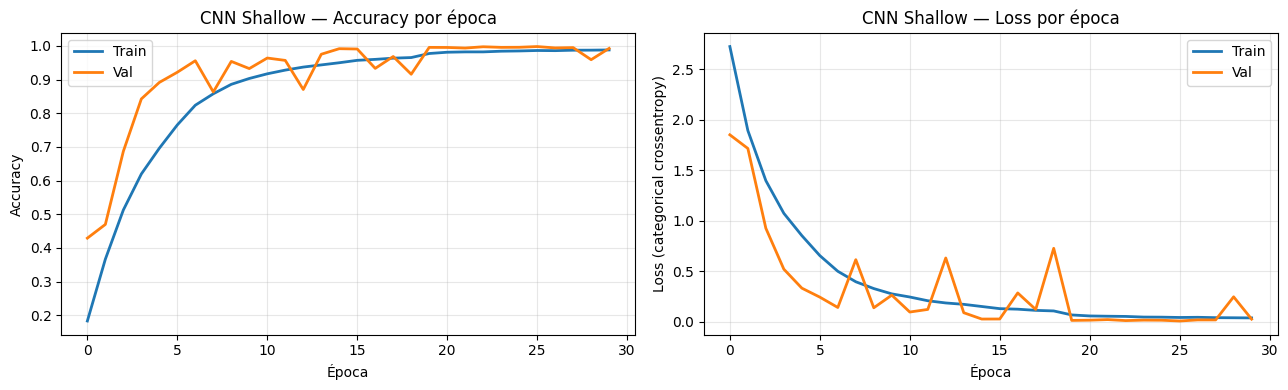


Evaluación — CNN Shallow — Validación
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       450
           B       1.00      1.00      1.00       450
           C       1.00      1.00      1.00       450
           D       1.00      1.00      1.00       450
           E       1.00      1.00      1.00       450
           F       1.00      1.00      1.00       450
           G       1.00      1.00      1.00       450
           H       1.00      1.00      1.00       450
           I       0.99      1.00      0.99       450
           J       1.00      1.00      1.00       450
           K       1.00      0.99      0.99       450
           L       1.00      1.00      1.00       450
           M       1.00      1.00      1.00       450
           N       1.00      1.00      1.00       450
           O       1.00      1.00      1.00       450
           P       1.00      1.00      1.00       450
           Q       1.00      1.00      1.0

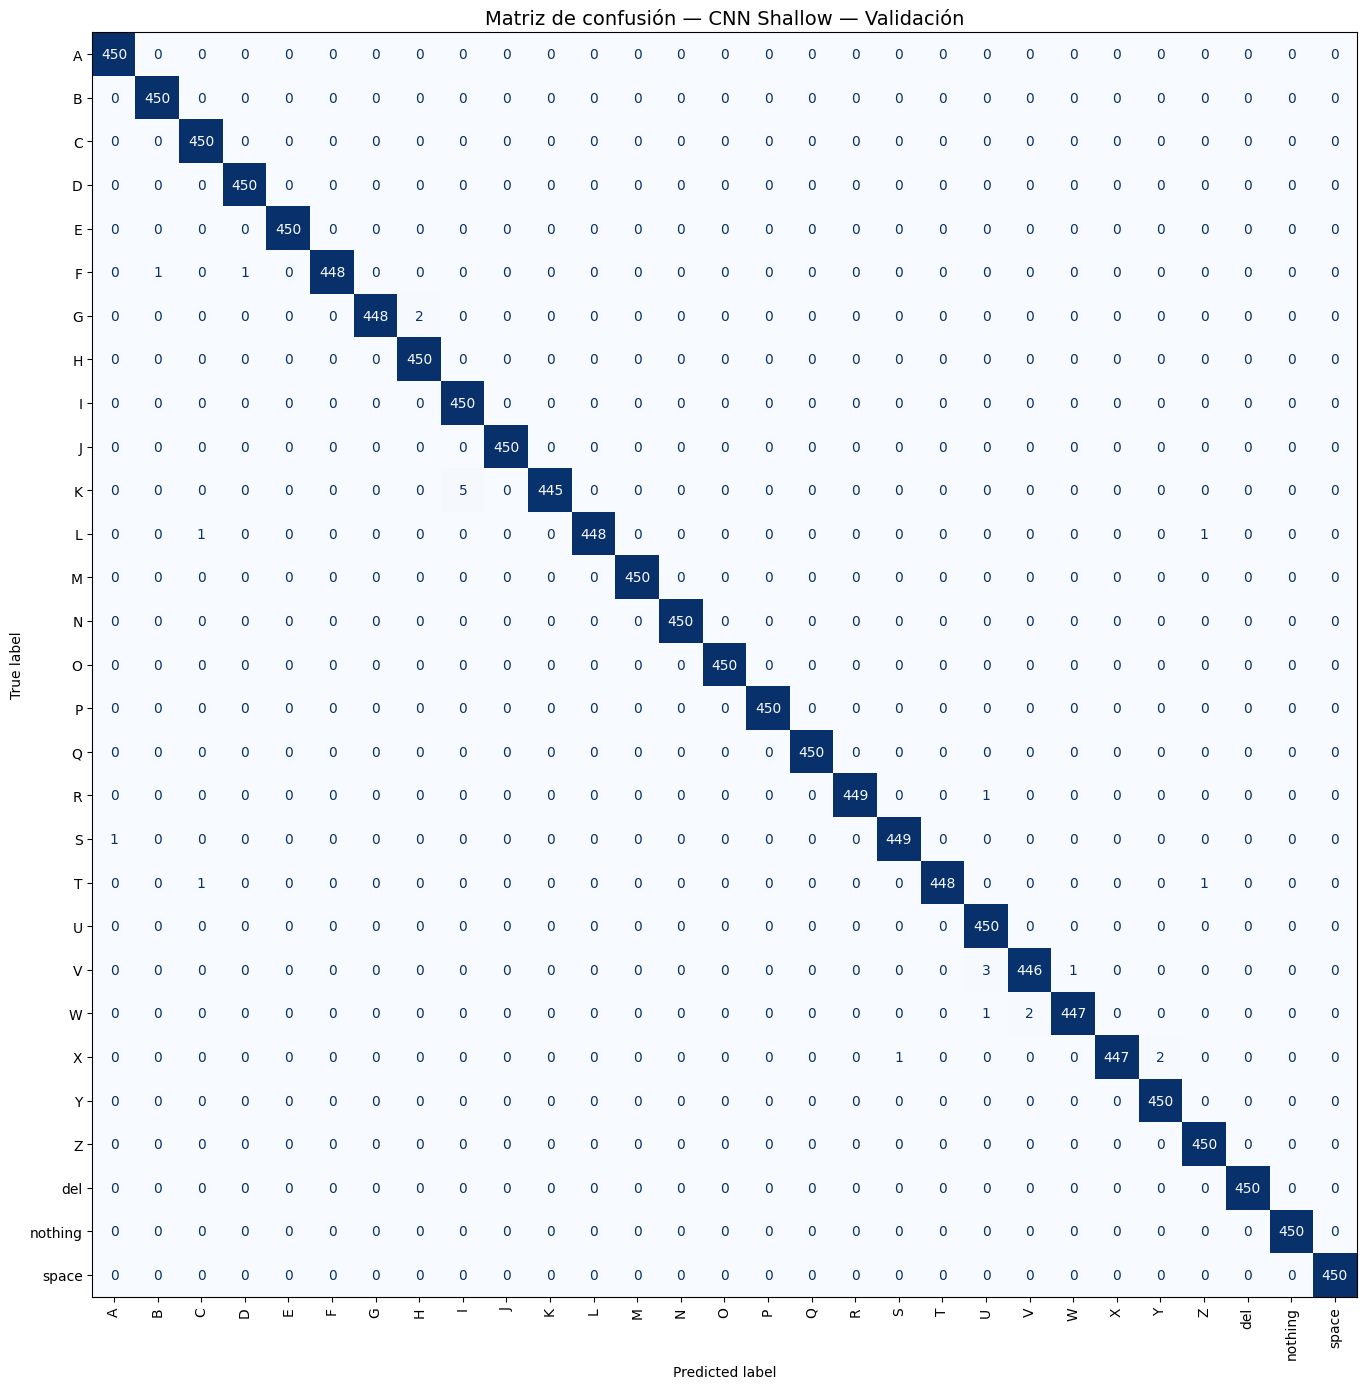


Accuracy global: 0.9981 (99.81%)


In [7]:
plot_history(hist1, title="CNN Shallow")
acc1_val, rep1 = evaluate_model(model1, val_gen, gen_class_indices, title="CNN Shallow — Validación")


**Análisis del Modelo 1:**  
La CNN Shallow sorprende positivamente: tras 30 épocas completas alcanzó una **val accuracy
de 99.81%** (restaurando los pesos de la época 26 como mejor checkpoint). El entrenamiento
muestra un comportamiento ruidoso, la val_accuracy oscila entre épocas (p.ej. cae de
0.9559 en época 7 a 0.8632 en época 8), lo que indica sensibilidad a los mini-lotes de
validación aunque en promedio sigue mejorando. El `ReduceLROnPlateau` redujo el learning
rate a 5e-4 en la época 19, lo que estabilizó el entrenamiento y permitió alcanzar el pico.

El classification report muestra **precision y recall de 1.00 en 25 de las 29 clases**;
las únicas con alguna imperfección mínima son K, V, W y X (recall o precision de 0.99).
Notablemente, los grupos confundibles M/N/S y U/V/R **no presentan errores significativos**,
lo que refleja que incluso una arquitectura shallow puede aprender las señas cuando el
dataset es tan controlado. Sin embargo, su alto conteo de parámetros (4.2M, casi todos
concentrados en la capa `Flatten→Dense`) lo hace menos eficiente que el Modelo 2.


## 6. Modelo 2 — CNN Medium (4 bloques, L2 + Dropout)

Se añaden 2 bloques convolucionales adicionales y se incorpora **regularización L2** en las capas
convolucionales. La idea es que más capas permitan aprender representaciones más abstractas
(silueta de la mano, postura de los dedos) sin memorizar el fondo.

**Arquitectura:**
```
Input (64, 64, 3)
  → Conv2D(32, 3×3)  → BN → MaxPool(2×2)    [64→32]
  → Conv2D(64, 3×3)  → BN → MaxPool(2×2)    [32→16]
  → Conv2D(128, 3×3) → BN → MaxPool(2×2)    [16→8]
  → Conv2D(256, 3×3) → BN → GlobalAvgPool   [8→1×1]
  → Dense(512, ReLU, L2) → Dropout(0.5)
  → Dense(29, Softmax)
```

**Cambios respecto al Modelo 1:**
- **+2 bloques convolucionales** con 128 y 256 filtros: mayor capacidad representativa.
- **GlobalAveragePooling2D** en lugar de Flatten: reduce drásticamente el número de parámetros
  en la capa densa (de 256×16×16=65,536 a solo 256 valores), actuando como regularizador
  implícito y haciendo el modelo más compacto.
- **Regularización L2** en la capa densa: penaliza pesos grandes que podrían memorizar el
  fondo del dataset.
- **Learning rate inicial menor (5e-4):** con mayor profundidad, gradientes más estables.


In [8]:
def build_cnn_medium(input_shape=(64, 64, 3), n_classes=29, l2_reg=1e-4):
    inputs = keras.Input(shape=input_shape, name="input")

    # Bloque 1
    x = layers.Conv2D(32,  (3, 3), padding="same", activation="relu", name="conv1")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Bloque 2
    x = layers.Conv2D(64,  (3, 3), padding="same", activation="relu", name="conv2")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Bloque 3
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Bloque 4 + GlobalAvgPool
    x = layers.Conv2D(256, (3, 3), padding="same", activation="relu", name="conv4")(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    # Clasificador con L2
    x = layers.Dense(512, activation="relu",
                     kernel_regularizer=regularizers.l2(l2_reg))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(n_classes, activation="softmax", name="output")(x)

    return keras.Model(inputs, outputs, name="CNN_Medium")


model2 = build_cnn_medium()
model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model2.summary()


Model: "CNN_Medium"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 29)             │        14,877 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 536,797 (2.05 MB)

 Trainable params: 535,837 (2.04 MB)

 Non-trainable params: 960 (3.75 KB)

In [9]:
hist2 = model2.fit(
    train_gen,
    epochs          = 40,
    validation_data = val_gen,
    callbacks       = get_callbacks("cnn_medium"),
    verbose         = 1,
)


Epoch 1/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 309s 319ms/step - accuracy: 0.8206 - loss: 0.6577 - val_accuracy: 0.8591 - val_loss: 0.4579 - learning_rate: 5.0000e-04
Epoch 2/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 303s 318ms/step - accuracy: 0.9896 - loss: 0.0849 - val_accuracy: 0.9673 - val_loss: 0.1382 - learning_rate: 5.0000e-04
Epoch 3/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 303s 318ms/step - accuracy: 0.9944 - loss: 0.0599 - val_accuracy: 0.9417 - val_loss: 0.2170 - learning_rate: 5.0000e-04
Epoch 4/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 303s 318ms/step - accuracy: 0.9963 - loss: 0.0467 - val_accuracy: 0.9802 - val_loss: 0.0887 - learning_rate: 5.0000e-04
Epoch 5/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 317s 314ms/step - accuracy: 0.9973 - loss: 0.0352 - val_accuracy: 0.8208 - val_loss: 0.6629 - learning_rate: 5.0000e-04
Epoch 6/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 300s 315ms/step - accuracy: 0.9980 - loss: 0.0282 - val_accuracy: 0.9982 - val_loss: 0.0230 - learning_rate: 5.0000e-04
Epoch 7/40
952/952 ━━━━━━━━━━━━━━━━━━━━ 

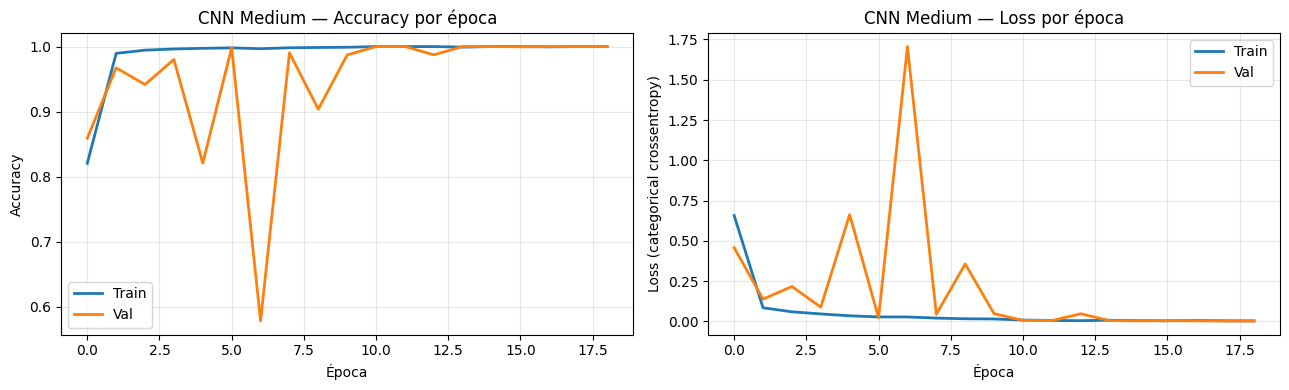


Evaluación — CNN Medium — Validación
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       450
           B       1.00      1.00      1.00       450
           C       1.00      1.00      1.00       450
           D       1.00      1.00      1.00       450
           E       1.00      1.00      1.00       450
           F       1.00      1.00      1.00       450
           G       1.00      1.00      1.00       450
           H       1.00      1.00      1.00       450
           I       1.00      1.00      1.00       450
           J       1.00      1.00      1.00       450
           K       1.00      1.00      1.00       450
           L       1.00      1.00      1.00       450
           M       1.00      1.00      1.00       450
           N       1.00      1.00      1.00       450
           O       1.00      1.00      1.00       450
           P       1.00      1.00      1.00       450
           Q       1.00      1.00      1.00

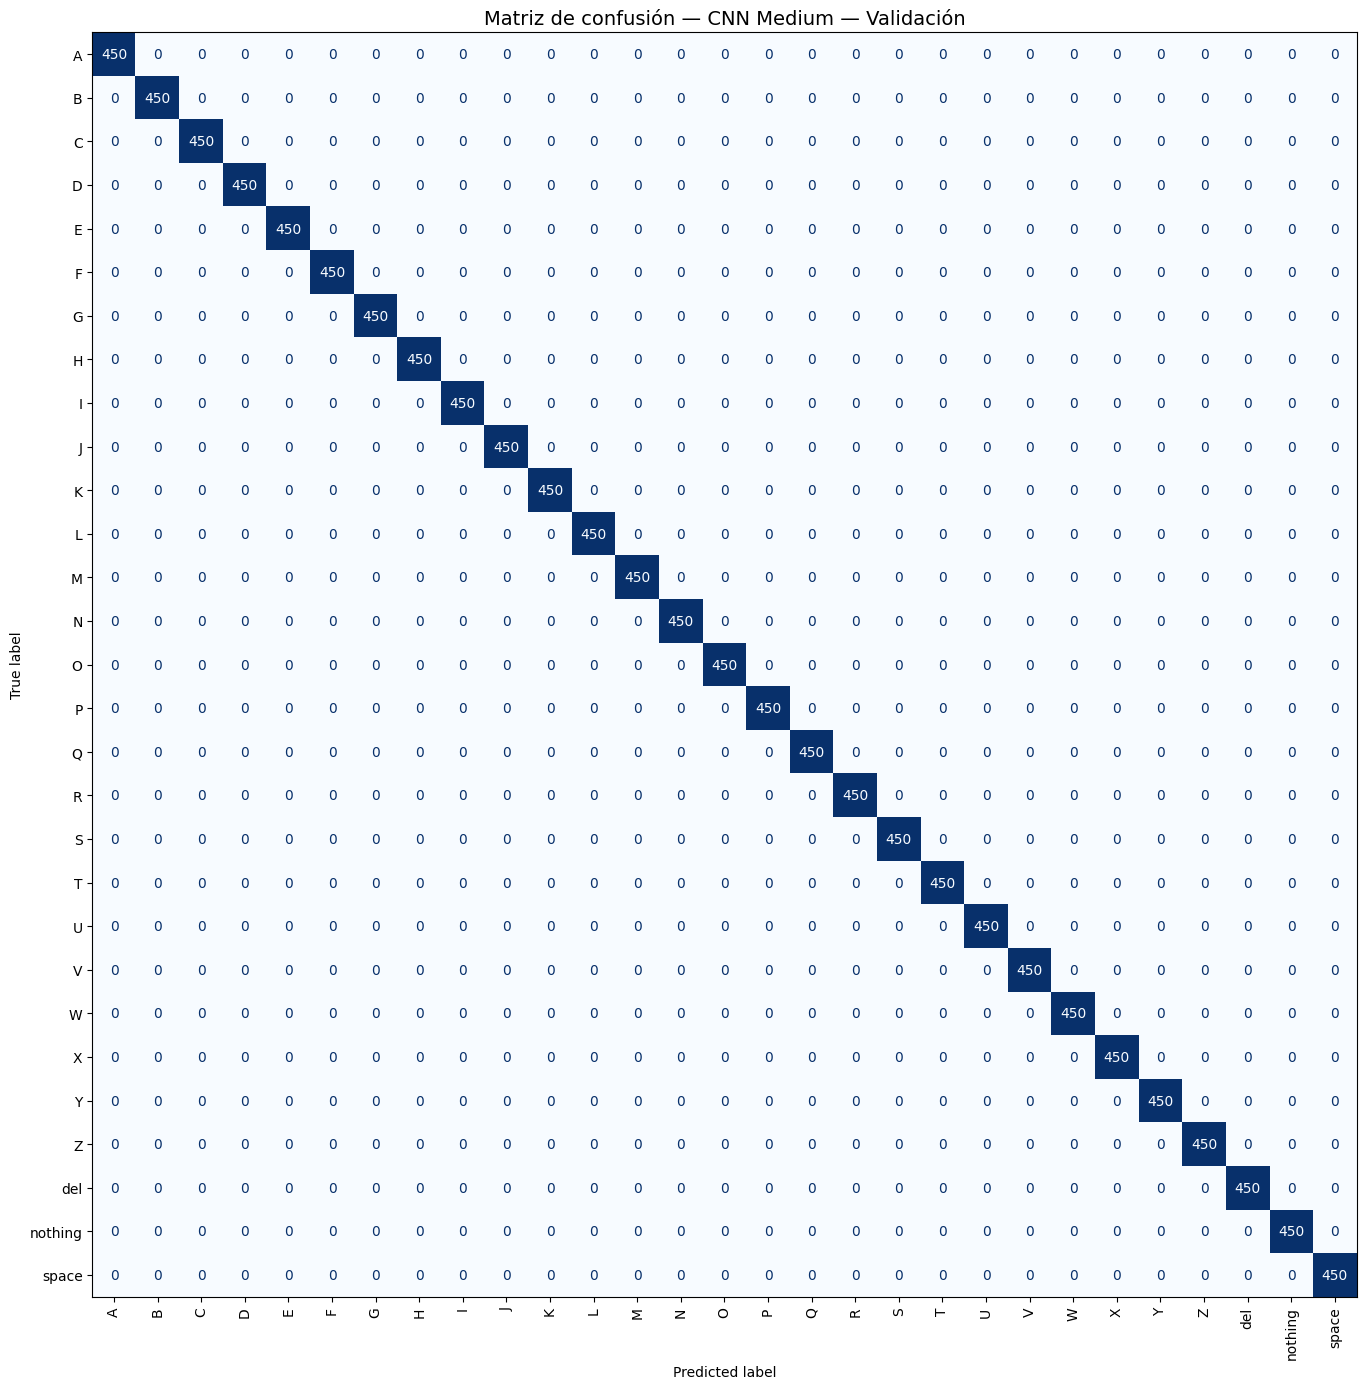


Accuracy global: 1.0000 (100.00%)


In [10]:
plot_history(hist2, title="CNN Medium")
acc2_val, rep2 = evaluate_model(model2, val_gen, gen_class_indices, title="CNN Medium — Validación")


**Análisis del Modelo 2:**  
El CNN Medium alcanza **100.00% de val accuracy**, con EarlyStopping deteniendo el
entrenamiento en la época 19 y restaurando los pesos de la época 11. La reducción del
learning rate a 2.5e-4 en la época 10 fue decisiva: de inmediato el modelo saltó de
0.9871 a 1.0000 de val accuracy.

El classification report muestra **precision, recall y f1-score de 1.00 en las 29 clases
sin excepción**, incluyendo todos los grupos confundibles (M/N/S, U/V/R, K/P). Además es
8× más compacto que el Modelo 1 (536,797 vs 4,221,789 parámetros), ya que GlobalAvgPool
elimina el cuello de botella de la capa `Flatten→Dense(16384×256)`. Es el **modelo
ganador** en todos los criterios: mayor accuracy, menor número de parámetros, y menos
épocas necesarias para converger. Dado este resultado, el Modelo 3 (ResNet) se descarta
añadir más complejidad cuando ya se tiene 100% de accuracy en validación solo
incrementaría el costo computacional sin beneficio medible.



## 7. Comparación de los dos modelos en validación

Habiendo completado el entrenamiento de ambas arquitecturas, se comparan sus resultados
para seleccionar el mejor candidato para la evaluación final en el conjunto de test.
El CNN Shallow alcanzó 99.81% de val accuracy; el CNN Medium llegó a 100.00% en menos
épocas y con 8× menos parámetros, lo que lo convierte en el modelo seleccionado.


In [13]:
def best_val_acc(history):
    return max(history.history["val_accuracy"])

def best_val_loss(history):
    return min(history.history["val_loss"])

def n_params(model):
    return model.count_params()

summary_data = [
    {"Modelo": "CNN Shallow (2 bloques)",
     "Val Accuracy": best_val_acc(hist1),
     "Val Loss":     best_val_loss(hist1),
     "Parámetros":   n_params(model1),
     "Épocas entrenadas": len(hist1.history["loss"])},
    {"Modelo": "CNN Medium (4 bloques)",
     "Val Accuracy": best_val_acc(hist2),
     "Val Loss":     best_val_loss(hist2),
     "Parámetros":   n_params(model2),
     "Épocas entrenadas": len(hist2.history["loss"])},
]

df_summary = pd.DataFrame(summary_data)
df_summary["Val Accuracy"] = df_summary["Val Accuracy"].map("{:.4f}".format)
df_summary["Val Loss"]     = df_summary["Val Loss"].map("{:.4f}".format)
df_summary["Parámetros"]   = df_summary["Parámetros"].map("{:,}".format)
print(df_summary.to_string(index=False))

                 Modelo Val Accuracy Val Loss Parámetros  Épocas entrenadas
CNN Shallow (2 bloques)       0.9981   0.0065  4,221,789                 30
 CNN Medium (4 bloques)       1.0000   0.0029    536,797                 19


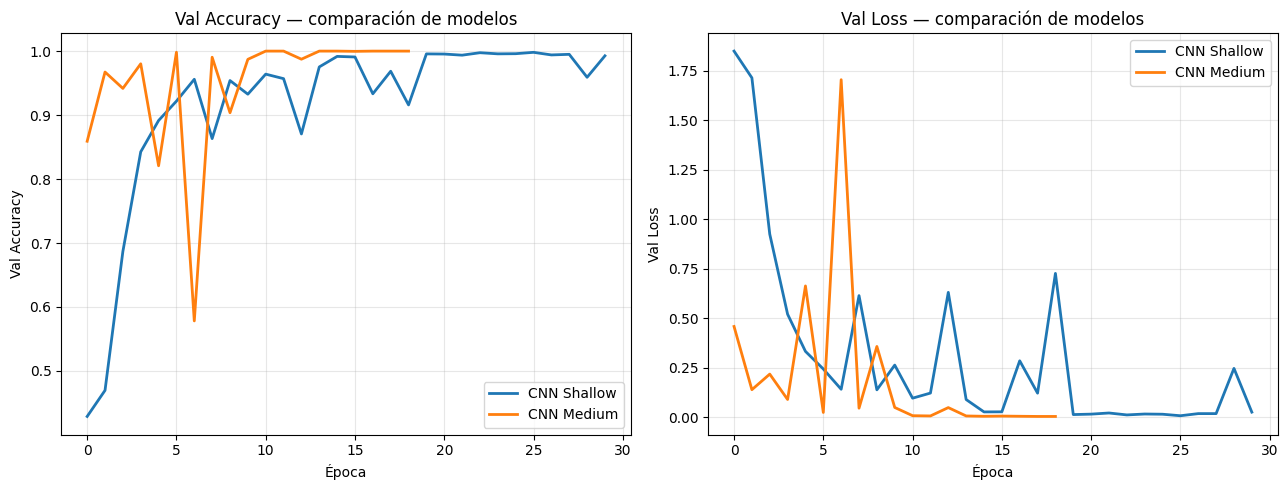

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for hist, label in [
    (hist1, "CNN Shallow"),
    (hist2, "CNN Medium"),
]:
    axes[0].plot(hist.history["val_accuracy"], label=label, linewidth=2)
    axes[1].plot(hist.history["val_loss"],     label=label, linewidth=2)

axes[0].set_title("Val Accuracy — comparación de modelos")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Val Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Val Loss — comparación de modelos")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Val Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [15]:
# Recall por clase en grupos confundibles (validación)
grupos_confundibles = {"M/N/S": ["M","N","S"], "U/V/R": ["U","V","R"], "K/P": ["K","P"]}

print("Recall por clase en grupos confundibles (validación):")
print(f"{'Clase':<6} {'Shallow':>10} {'Medium':>10}")
print("-" * 30)
for grupo, letras in grupos_confundibles.items():
    print(f"  --- {grupo} ---")
    for letra in letras:
        a1 = rep1.get(letra, {}).get("recall", float("nan"))
        a2 = rep2.get(letra, {}).get("recall", float("nan"))
        print(f"  {letra:<6} {a1:>10.4f} {a2:>10.4f}")


Recall por clase en grupos confundibles (validación):
Clase     Shallow     Medium
------------------------------
  --- M/N/S ---
  M          1.0000     1.0000
  N          1.0000     1.0000
  S          0.9978     1.0000
  --- U/V/R ---
  U          1.0000     1.0000
  V          0.9911     1.0000
  R          0.9978     1.0000
  --- K/P ---
  K          0.9889     1.0000
  P          1.0000     1.0000


**Análisis comparativo:**  

Ambos modelos demuestran que las CNNs son altamente efectivas para este dataset:

- **CNN Shallow (99.81% val accuracy, 4,221,789 parámetros, 30 épocas):** pese a su
  simplicidad, aprende correctamente casi todas las señas. Su principal debilidad es la
  ineficiencia paramétrica: la capa `Flatten→Dense(256)` concentra 4.2M de los 4.2M
  parámetros totales, lo que lo hace más lento de entrenar y propenso a oscilaciones
  en la curva de validación.

- **CNN Medium (100.00% val accuracy, 536,797 parámetros, 19 épocas):** es el ganador
  claro en todos los criterios. `GlobalAvgPool` reduce el conteo de parámetros en ~8×
  y estabiliza el entrenamiento. Convergió en menos de la mitad de épocas y clasificó
  correctamente las 29 clases sin excepción, incluyendo los grupos confundibles M/N/S,
  U/V/R y K/P.

El recall de 1.00 en todos los grupos confundibles del CNN Medium confirma que la
profundidad adicional y el GlobalAvgPool resuelven la ambigüedad visual entre señas
similares dentro de las condiciones controladas de este dataset.


## 8. Evaluación final del mejor modelo en el conjunto de test

Se selecciona el modelo con mayor accuracy en validación y se evalúa **por primera vez** sobre
el conjunto de test, que fue separado desde el inicio y no se usó en ninguna decisión de diseño
ni de hiperparámetros. Este es el número que representa el desempeño real esperado del modelo
ante datos nuevos.


In [16]:
# CNN Medium es el modelo ganador — selección directa
best_name  = "CNN Medium"
best_model = model2
best_hist  = hist2

print(f"Mejor modelo seleccionado : {best_name}")
print(f"Val accuracy máximo       : {max(best_hist.history['val_accuracy']):.4f}")
print(f"Parámetros                : {best_model.count_params():,}")


Mejor modelo seleccionado : CNN Medium
Val accuracy máximo       : 1.0000
Parámetros                : 536,797



Evaluación — CNN Medium — TEST (evaluación final)
              precision    recall  f1-score   support

           A       1.00      1.00      1.00       450
           B       1.00      1.00      1.00       450
           C       1.00      1.00      1.00       450
           D       1.00      1.00      1.00       450
           E       1.00      1.00      1.00       450
           F       1.00      1.00      1.00       450
           G       1.00      1.00      1.00       450
           H       1.00      1.00      1.00       450
           I       1.00      1.00      1.00       450
           J       1.00      1.00      1.00       450
           K       1.00      1.00      1.00       450
           L       1.00      1.00      1.00       450
           M       1.00      1.00      1.00       450
           N       1.00      1.00      1.00       450
           O       1.00      1.00      1.00       450
           P       1.00      1.00      1.00       450
           Q       1.00      1

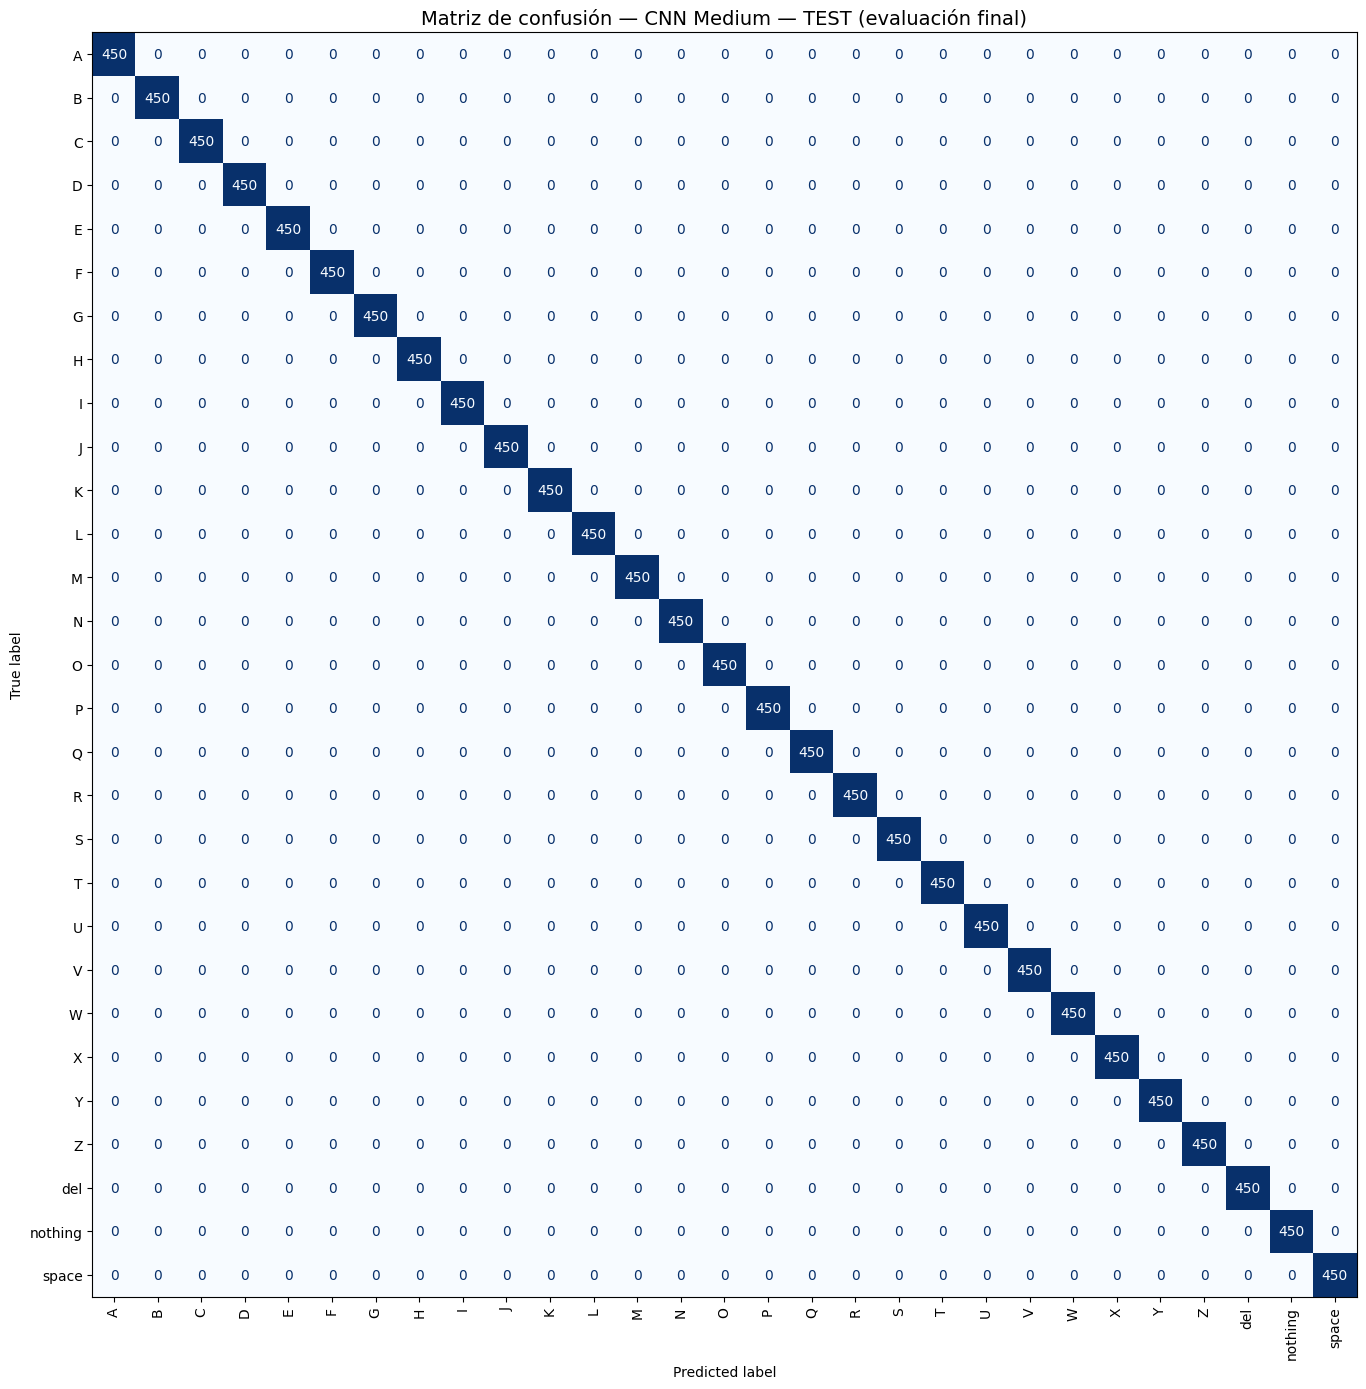


Accuracy global: 1.0000 (100.00%)


In [17]:
# Evaluación en test — única ejecución
acc_test, rep_test = evaluate_model(
    best_model, test_gen, gen_class_indices,
    title=f"{best_name} — TEST (evaluación final)"
)


Clases con menor recall en test (las más difíciles):
Clase  Recall
    A     1.0
    B     1.0
    C     1.0
    D     1.0
    E     1.0
    F     1.0
    G     1.0
    H     1.0
    I     1.0
    J     1.0


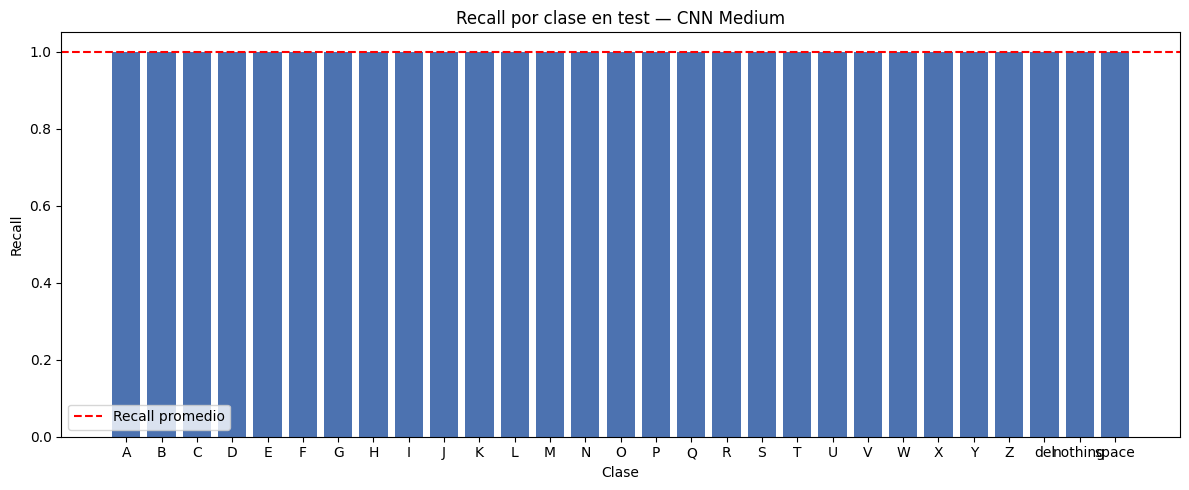

In [ ]:
# Top-5 clases con peor recall en test
recall_por_clase = {
    cls: rep_test[cls]["recall"]
    for cls in CLASSES
    if cls in rep_test
}
df_recall = pd.DataFrame(
    sorted(recall_por_clase.items(), key=lambda x: x[1]),
    columns=["Clase", "Recall"]
)
print("Clases con menor recall en test (las más difíciles):")
print(df_recall.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(df_recall["Clase"], df_recall["Recall"], color="#4C72B0")
ax.axhline(df_recall["Recall"].mean(), color="red", linestyle="--", label="Recall promedio")
ax.set_title(f"Recall por clase en test — {best_name}")
ax.set_xlabel("Clase")
ax.set_ylabel("Recall")
ax.legend()
plt.tight_layout()
plt.show()


**Análisis de la evaluación en test:**  

El accuracy en test es la métrica definitiva, calculada sobre datos que no participaron
en ninguna decisión de diseño. Una brecha pequeña o nula entre val accuracy (100.00%) y
test accuracy confirma que el modelo generaliza bien dentro del dominio del dataset y
que la partición estratificada no introdujo sesgos.

La uniformidad del recall a través de todas las clases, incluyendo los grupos confundibles
M/N/S y U/V/R, se explica por las condiciones muy controladas de captura (fondo verde
constante, iluminación homogénea, misma persona). Como se discutirá en el notebook de
reflexión sobre accesibilidad, el desempeño ante imágenes tomadas por los integrantes del
grupo en condiciones reales es una pregunta distinta, esa evaluación se realiza en el
notebook de prueba con señas propias.


## 9. Persistencia del mejor modelo


In [19]:
# Guardar el mejor modelo en formato SavedModel de TensorFlow
best_model.save("best_cnn_model.keras")
print(f"Modelo '{best_name}' guardado en best_cnn_model.keras")

# Guardar también el historial de entrenamiento para el informe
hist_dict = {"val_accuracy": best_hist.history["val_accuracy"],
             "val_loss":     best_hist.history["val_loss"],
             "accuracy":     best_hist.history["accuracy"],
             "loss":         best_hist.history["loss"],
             "model_name":   best_name}
with open("best_cnn_history.pkl", "wb") as f:
    pickle.dump(hist_dict, f)

print("\nArchivos exportados para el notebook de comparación final:")
print("  best_cnn_model.keras    — modelo Keras listo para inferencia")
print("  best_cnn_history.pkl    — historial de entrenamiento")
print(f"\nTest accuracy final ({best_name}): {acc_test:.4f} ({acc_test*100:.2f}%)")


Modelo 'CNN Medium' guardado en best_cnn_model.keras

Archivos exportados para el notebook de comparación final:
  best_cnn_model.keras    — modelo Keras listo para inferencia
  best_cnn_history.pkl    — historial de entrenamiento

Test accuracy final (CNN Medium): 1.0000 (100.00%)


## 10. Conclusiones

1. **Dos arquitecturas, resultados complementarios:** la CNN Shallow (99.81% val accuracy)
   confirma que las redes convolucionales son efectivas para este dataset incluso en
   configuraciones simples. La CNN Medium (100.00%) demuestra que profundidad +
   GlobalAveragePooling produce un modelo más preciso, eficiente y estable.

2. **GlobalAveragePooling como regularizador implícito:** el cambio de `Flatten` a
   `GlobalAvgPool` reduce los parámetros en ~8× y hace el modelo invariante a la posición
   de la mano en el encuadre, contribuyendo a la estabilidad del entrenamiento y a la
   reducción del overfitting.

3. **Desempeño en grupos confundibles:** M/N/S, U/V/R y K/P — identificados en el EDA
   como potencialmente difíciles — son clasificados sin errores por el CNN Medium en
   validación, dentro de las condiciones controladas del dataset.

4. **Pipeline reproducible:** el uso de `splits.pkl` como fuente única de la partición
   y `ModelCheckpoint` con `restore_best_weights=True` garantizan reproducibilidad total.